<a href="https://colab.research.google.com/github/jadesjr/interpreteur-fractran/blob/main/Copie_de_jolies_algo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importation des Bibliothèques utiles

In [140]:
import numpy as np
import matplotlib.pyplot as plt
import math
import time

#Création d'un nuage de point alétoire et tracé

In [141]:
def creation_nuage(nb_point,x_min, x_max, y_min, y_max) :
  L_points = []
  for i in range (0, nb_point):
    x=np.random.uniform(x_min,x_max)
    y=np.random.uniform(y_min,y_max)
    L_points.append((x,y))
  return L_points


def tracer_nuage(L_points) :
  x_coords = [point[0] for point in L_points]
  y_coords = [point[1] for point in L_points]

  plt.figure(figsize=(10, 10))
  plt.scatter(x_coords, y_coords, color="blue", label="Points")
  plt.title("Nuage de points aléatoire")
  plt.ylabel("y")
  plt.xlabel("x")
  plt.grid()
  plt.legend()
  plt.show()

def tracer_nuage_enveloppe(L_points,L_enveloppe):
  x_coords = [point[0] for point in L_points]
  y_coords = [point[1] for point in L_points]
  x= [point[0] for point in L_enveloppe]+[L_enveloppe[0][0]]
  y= [point[1] for point in L_enveloppe]+ [L_enveloppe[0][1]]
  plt.figure(figsize=(10, 10))
  plt.scatter(x_coords, y_coords, color="blue", label="Points")
  plt.plot(x,y,color='red',label='enveloppe')
  plt.title("Nuage de points avec son enveloppe")
  plt.ylabel("y")
  plt.xlabel("x")
  plt.grid()
  plt.legend()
  plt.show()




Exemple de nuage généré

[(5.594221523312082, 14.991748213311912), (11.011211351439592, 13.045049600694787), (17.964863979463352, 16.20064709224246), (7.242103380140987, 19.83560579533124), (14.342085490590726, 4.240692111634862), (9.652175669967633, 17.902177117929632), (19.500423892515094, 19.50699785850867), (6.131189582011778, 14.49380267101191), (6.572186537716222, 13.307959947597661), (17.47412400257639, 0.6172612554628176)]


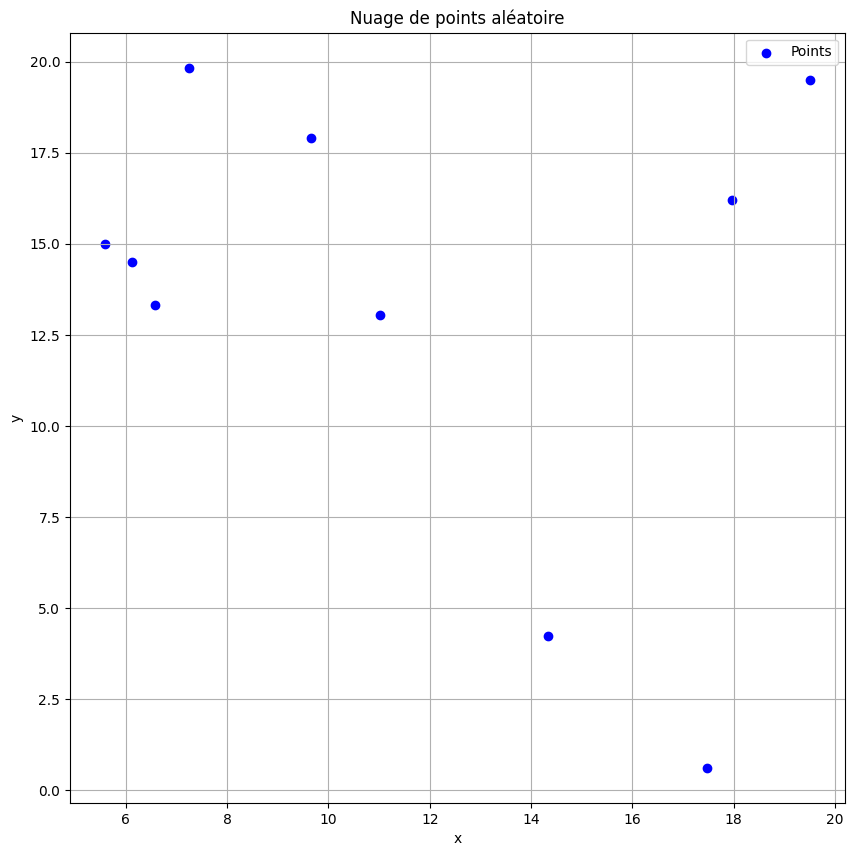

In [142]:
nb_point = 10
x_min, x_max = 0, 20
y_min, y_max = 0, 20 #valeurs prise arbitrairement
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
print(nuage)
tracer_nuage(nuage)


# Sklansky

In [143]:
def produit_vectoriel(p1,p2,p3):
  droite1=[p2[0]-p1[0],p2[1]-p1[1]]
  droite2=[p3[0]-p2[0],p3[1]-p2[1]]
  produit = droite1[0]*droite2[1]-droite1[1]*droite2[0]
  return produit


def enveloppe_convexe_sklansky(nuage):
  #l'alogithme fonctionne si ces points sont triés selon leur coordonnées (x puis y)
    if len(nuage) <= 2:
        return nuage

    enveloppe = [nuage[0], nuage[1]]
    inferieure = []
    superieure = []
    for p in nuage:
        while len(inferieure) >= 2 and produit_vectoriel(inferieure[-2], inferieure[-1], p) < 0:
            inferieure.pop()
        inferieure.append(p)

    for p in reversed(nuage):
        while len(superieure) >= 2 and produit_vectoriel(superieure[-2], superieure[-1], p) < 0:
            superieure.pop()
        superieure.append(p)

    return inferieure[:-1] + superieure[:-1]


[(5.594221523312082, 14.991748213311912), (6.572186537716222, 13.307959947597661), (14.342085490590726, 4.240692111634862), (17.47412400257639, 0.6172612554628176), (19.500423892515094, 19.50699785850867), (7.242103380140987, 19.83560579533124)]


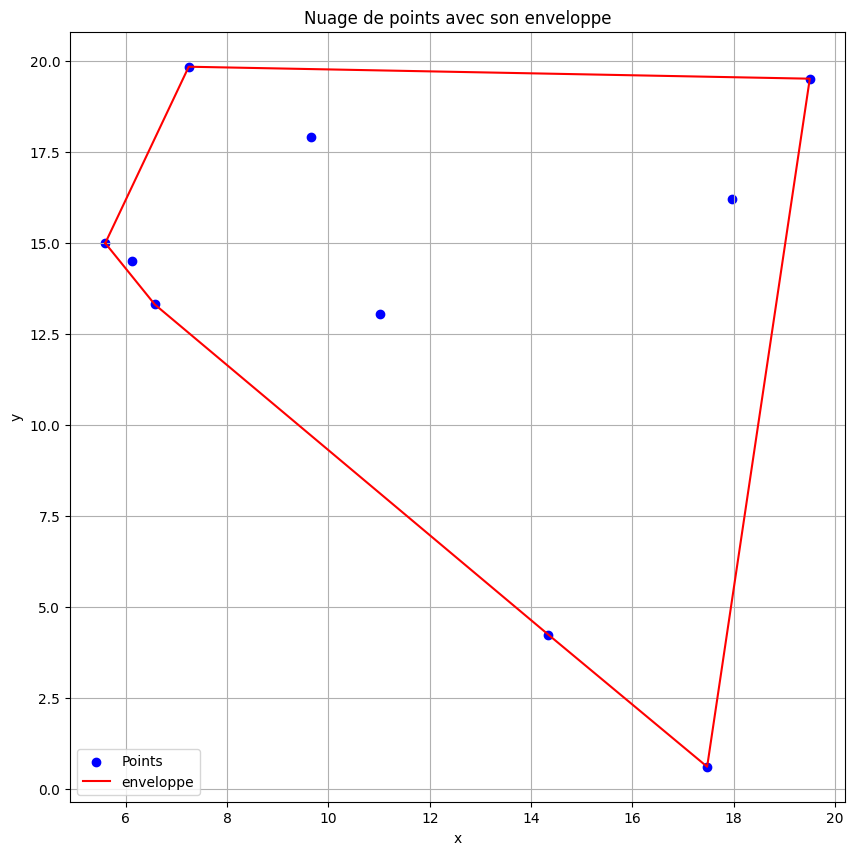

In [144]:
nuage = sorted(nuage)
enveloppe=enveloppe_convexe_sklansky(nuage)
print(enveloppe)
tracer_nuage_enveloppe(nuage,enveloppe)


# Méthode des angles polaires

In [145]:
def milieu(p1,p2,p3):
  return [(p1[0]+p2[0]+p3[0])/3,(p1[1]+p2[1]+p3[1])/3]

def produit_scalairre(d1,d2):
  return d1[0]*d2[0]+d1[1]*d2[1]

def norme(d):
  return np.sqrt(d[0]**2+d[1]**2)

def enveloppe_convexe_polaire(nuage):
  if len(nuage)<=2:
    return nuage
  #on prend le milieu de trois points du nuage
  m=milieu(nuage[0],nuage[-1],nuage[len(nuage)//2+1]) #points choisis de manière purement arbitraire
  angles=[]
  d_ref=[m[0]-nuage[0][0],m[1]-nuage[0][1]]
  #on trie les points en fonction de leur angle par au point créé
  for p in nuage:
    droite=[m[0]-p[0],m[1]-p[1]]
    angle=np.arccos(produit_scalairre(droite,d_ref)/(norme(droite)*norme(d_ref)))
    angles.append((p,angle))
  angles=sorted(angles,key=lambda angles:angles[1])
  nuage_trie=[t[0]for t in angles]
  # On fais sklansky
  enveloppe=enveloppe_convexe_sklansky(nuage_trie)
  return enveloppe







/tmp/ipykernel_929/163402017.py:20: RuntimeWarning: invalid value encountered in arccos
  angle=np.arccos(produit_scalairre(droite,d_ref)/(norme(droite)*norme(d_ref)))


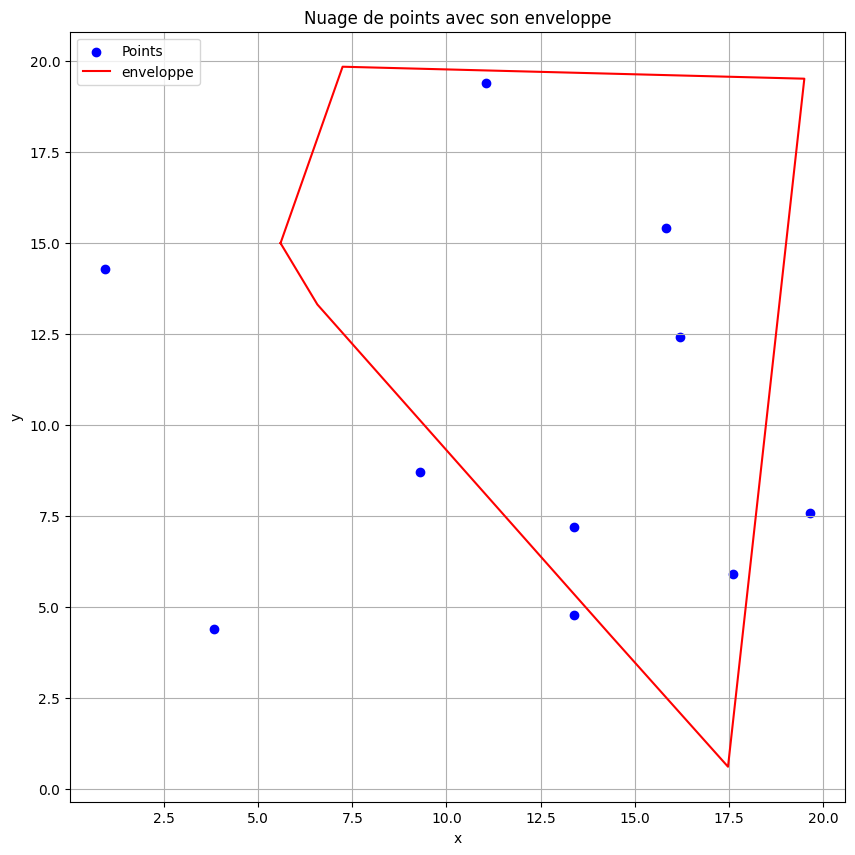

In [146]:
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
enveloppe_convexe_polaire(nuage)
tracer_nuage_enveloppe(nuage,enveloppe)

On voit que cela ne fonctionne pas car sklansky nécessite qu'on ai trié les points en fonctions de leur coordonnées. On peut faire un nouveau code pour sklansky qui fonctionne pour des coordonnée trié de manière polaire

In [147]:
def enveloppe_convexe_sklansky_polaire(nuage):
    if len(nuage) <= 2:
        return nuage

    enveloppe = []
    for p in nuage:
        while len(enveloppe) >= 2 and produit_vectoriel(enveloppe[-2], enveloppe[-1], p) < 0:
            enveloppe.pop()
        enveloppe.append(p)

# On gére le raccordement entre le premier et le dernier point de l'enveloppe
    while len(enveloppe) > 2 and produit_vectoriel(enveloppe[-2], enveloppe[-1], enveloppe[0]) < 0 and produit_vectoriel(enveloppe[-1], enveloppe[0], enveloppe[1]) < 0:
      #On retire celui qui pose problème (le 1er ou le dernier), celui qui fais un angle rentrant quand on le joint avec l'autre bout
      if produit_vectoriel(enveloppe[-2], enveloppe[-1], enveloppe[0]) <= 0:
            enveloppe.pop()
      elif produit_vectoriel(enveloppe[-1], enveloppe[0], enveloppe[1]) <= 0:
            enveloppe.pop(0)

    return enveloppe

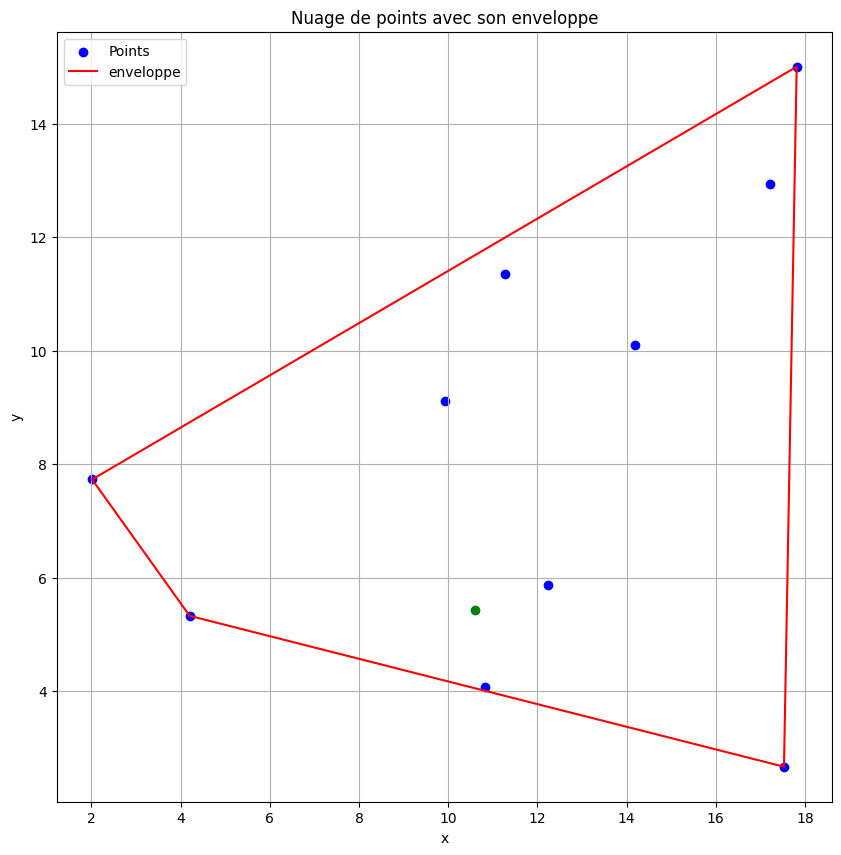

In [148]:
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
enveloppe= enveloppe_convexe_polaire(nuage)
m=milieu(nuage[0],nuage[-1],nuage[len(nuage)//2+1])

x_coords = [point[0] for point in nuage]
y_coords = [point[1] for point in nuage]
x= [point[0] for point in enveloppe]+[enveloppe[0][0]]
y= [point[1] for point in enveloppe]+ [enveloppe[0][1]]

plt.figure(figsize=(10, 10))
plt.scatter([m[0]],[m[1]],color='g')
plt.scatter(x_coords, y_coords, color="blue", label="Points")
plt.plot(x,y,color='red',label='enveloppe')
plt.title("Nuage de points avec son enveloppe")
plt.ylabel("y")
plt.xlabel("x")
plt.grid()
plt.legend()
plt.show()


On voit que cela ne fonctionne pas tout le temps. On peu esseayer de changer le point de référence et prendre le barycentre du nuage

In [149]:

def enveloppe_convexe_polaire_bis(nuage):
  if len(nuage)<=2:
    return nuage
  m=np.mean(np.array(nuage), axis=0) #on prend le barycentre
  angles=[]
  d_ref=[m[0]-nuage[0][0],m[1]-nuage[0][1]]

  for p in nuage:
    droite=[m[0]-p[0],m[1]-p[1]]
    angle=np.arccos(produit_scalairre(droite,d_ref)/(norme(droite)*norme(d_ref)))

    angles.append((p,angle))
  angles=sorted(angles,key=lambda angles:angles[1])
  nuage_trie=[t[0]for t in angles]

  enveloppe=enveloppe_convexe_sklansky_polaire(nuage_trie)
  return enveloppe


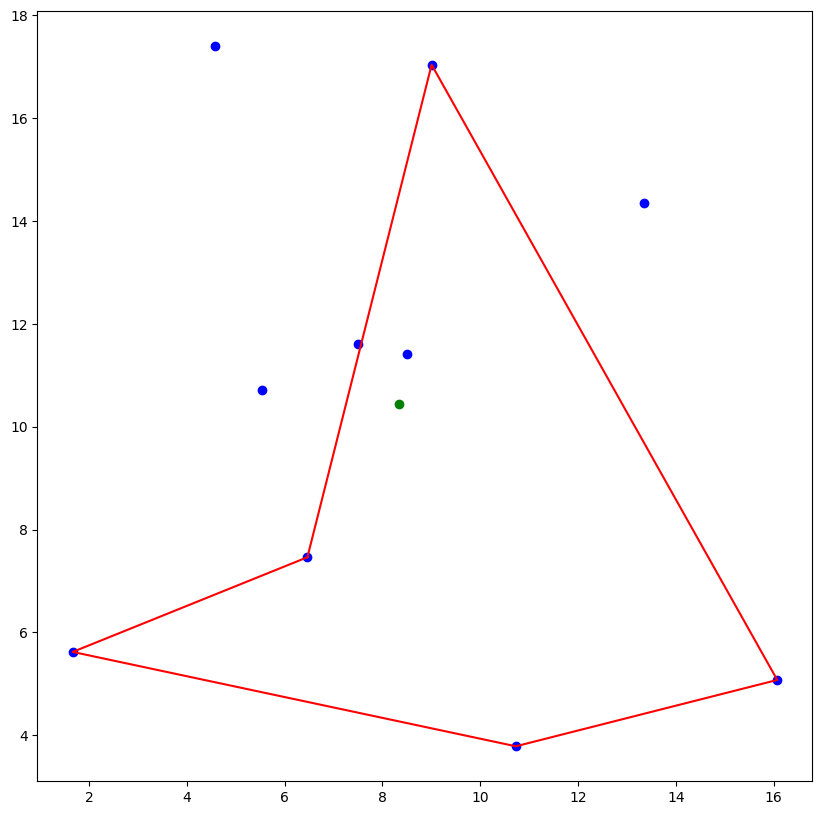

In [150]:
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
enveloppe= enveloppe_convexe_polaire_bis(nuage)
m=np.mean(np.array(nuage), axis=0) # Correction : ajout de axis=0

x_coords = [point[0] for point in nuage]
y_coords = [point[1] for point in nuage]
x= [point[0] for point in enveloppe]+[enveloppe[0][0]]
y= [point[1] for point in enveloppe]+ [enveloppe[0][1]]

plt.figure(figsize=(10, 10))
plt.scatter([m[0]],[m[1]],color='g')
plt.scatter(x_coords, y_coords, color="blue", label="Points")
plt.plot(x,y,color='red',label='enveloppe')

Cela ne fonctionne toujours pas. On a aussi un problème de trigonométrie, en effet np.arccos renvoie toujours une valeur comprise entre $0$ et $\pi$ radians. Donc il n'y à aucune distinction entre un point situé à $\pi/2$ ou $3\pi/2$ par exemple.

On va essayer avec une autre fonction trigonométrique : atan2

In [151]:
def enveloppe_convexe_polaire_ter(nuage):
  if len(nuage)<=2:
    return nuage
  m=np.mean(np.array(nuage), axis=0) #on prend le barycentre
  angles=[]

  for p in nuage:
    angle = math.atan2(p[1] - m[1], p[0] - m[0])
    angles.append((p,angle))

  angles=sorted(angles,key=lambda angles:angles[1])
  nuage_trie=[t[0]for t in angles]

  enveloppe=enveloppe_convexe_sklansky_polaire(nuage_trie)
  return enveloppe



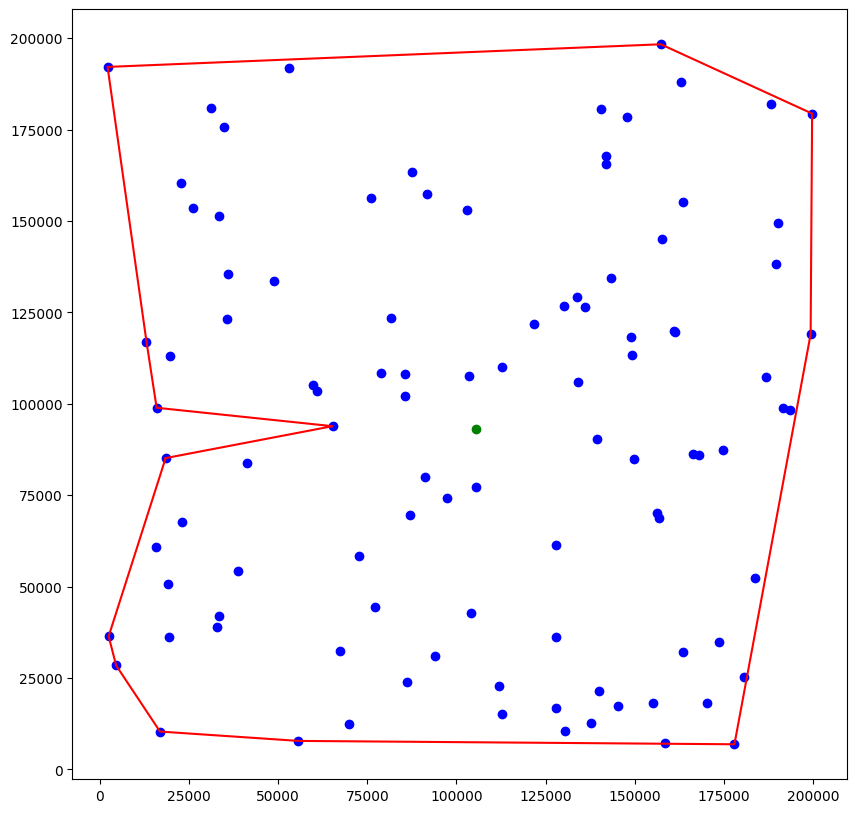

In [175]:
nuage = creation_nuage(100,x_min, x_max, y_min, y_max)
enveloppe= enveloppe_convexe_polaire_ter(nuage)
m=np.mean(np.array(nuage), axis=0)

x_coords = [point[0] for point in nuage]
y_coords = [point[1] for point in nuage]
x= [point[0] for point in enveloppe]+[enveloppe[0][0]]
y= [point[1] for point in enveloppe]+ [enveloppe[0][1]]

plt.figure(figsize=(10, 10))
plt.scatter([m[0]],[m[1]],color='g')
plt.scatter(x_coords, y_coords, color="blue", label="Points")
plt.plot(x,y,color='red',label='enveloppe')

Cela ne fonctionne toujours pas...

# Divide and conquer




In [153]:
#Nuage de point avec lequel on travail
nb_point = 10
x_min, x_max = 0, 20
y_min, y_max = 0, 20 #valeurs prise arbitrairement
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)

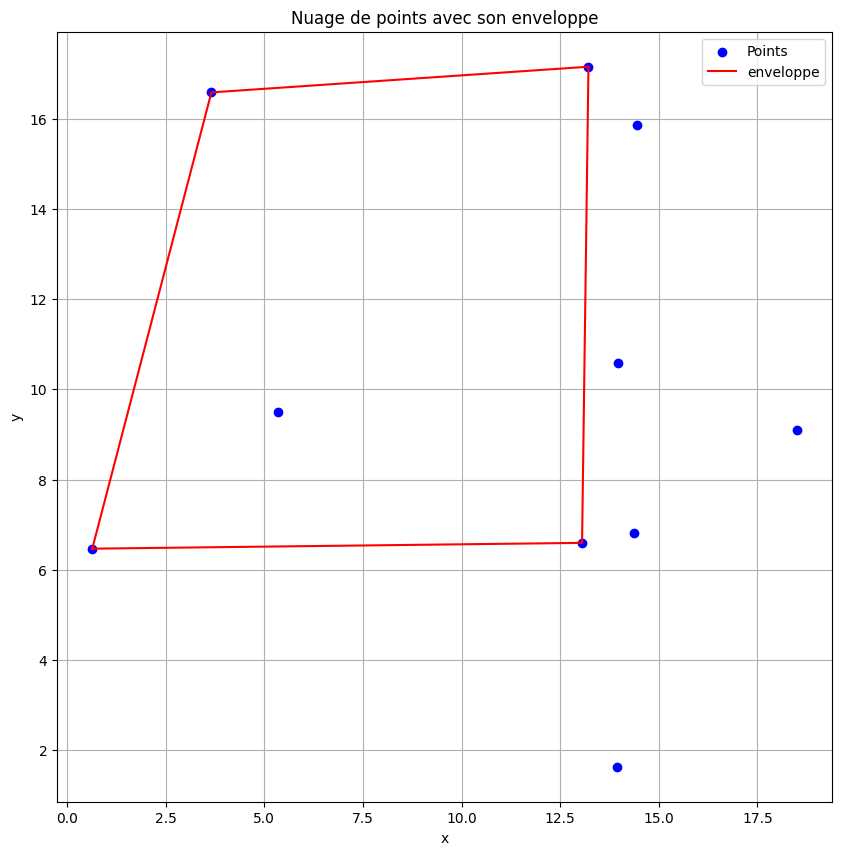

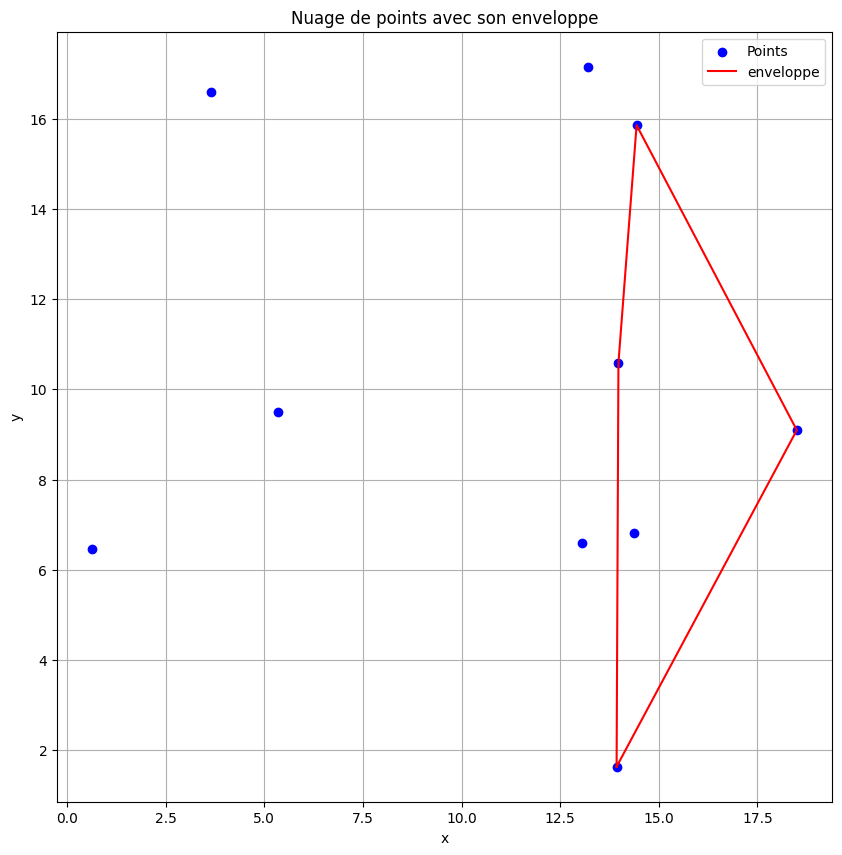

IndexError: list index out of range

In [154]:
#1ere etape : trie de points en fonction des abscisses croissante
def tri_x_croissant(L_points):
  points=L_points.copy()
  for i in range (0, len(points)):
    i_min=i
    for j in range (i+1, len(points)):
      if points[j][0]<points[i_min][0]:
        i_min=j
    if i_min != i:
      t=points[i]
      points[i]=points[i_min]
      points[i_min]=t
  return points

L_points_tries = tri_x_croissant(nuage)

#2eme etape : "Divide" en coupe au milieu en deux sous groupe puis on applique Sklansky
index_milieu = len(L_points_tries)//2
sous_ensemble_gauche = L_points_tries[:index_milieu]
sous_ensemble_droite = L_points_tries[index_milieu:]

gauche=enveloppe_convexe_sklansky(sous_ensemble_gauche)
droite=enveloppe_convexe_sklansky(sous_ensemble_droite)

tracer_nuage_enveloppe(nuage,gauche)
tracer_nuage_enveloppe(nuage,droite)

#3eme etape : Jonction grâce au tangente, c'est la partie la plus complexe à coder.
#pour la recherche de la tangente il faut savoir si on étudie la tangente du haut ou du bas
#donc on ajoute un argument de type boléen à la fonction pour faire les deux cas
def recherche_tangente(gauche, droite, i, j, sup=True ):
  m= True #condition de basculement
  while m :
    m=False
    if sup :
      if produit_vectoriel(droite[j], gauche[i], gauche[i-1])>0:
        i = (i - 1)
        m = True
      elif produit_vectoriel(gauche[i], droite[j], droite[j + 1]) < 0:
        j = (j + 1)
        m = True
    else:
      if produit_vectoriel(gauche[i], droite[j], droite[j - 1]) > 0:
        j = (j - 1)
        m = True
      elif produit_vectoriel(droite[j], gauche[i], gauche[i + 1]) < 0:
        i = (i + 1)
        m = True
  return i,j


def point_fusion_enveloppe(gauche, droite):
    n_g, n_d = len(gauche), len(droite)
    i = 0  # On suppose au départ que c'est le 1er point
    for k in range(1, n_g):
      if gauche[k][0] > gauche[i][0]:
        i = k
    j = 0 #de meme à droite
    for k in range(1, n_d):
      if droite[k][0] < droite[j][0]:
        j = k
    return i,j

i, j = point_fusion_enveloppe(gauche, droite)
i_sup, j_sup = recherche_tangente(gauche, droite, i, j, sup=True)
i_inf, j_inf = recherche_tangente(gauche, droite, i_sup, j_sup, sup=False)

envellope_fusionnee=[]
indice_gauche=i_inf
while indice_gauche != i_sup+1 :
  envellope_fusionnee.append(gauche[indice_gauche])
  indice_gauche=indice_gauche+1

indice_droite=j_sup
while indice_droite != j_inf+1 :
  envellope_fusionnee.append(gauche[indice_droite])
  indice_droite=indice_droite+1

tracer_nuage_enveloppe(nuage,envellope_fusionnee)

La version ci-dessus à un problème car on index out of range au niveau de la jonction. On pioche un indice de droite sur l'enveloppe de gauche donc ca ne marche
Il faut utiliser le modulo sur les fonctions de recherche de tangente et de fusion.
Autre problème relevé après : i_inf, j_inf = recherche_tangente(gauche, droite, i_sup, j_sup, sup=False) n'est pas correcte car la tangente inférieur ne peux pas démarrer du haut, il faut reprendre au point i,j initial


Version finale ⬇

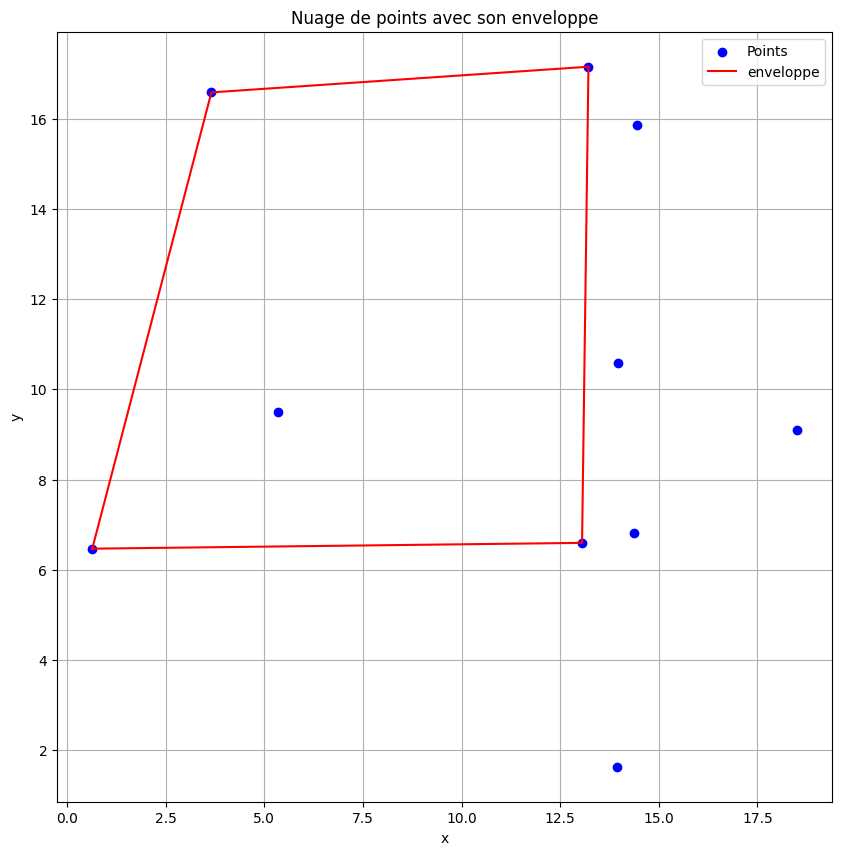

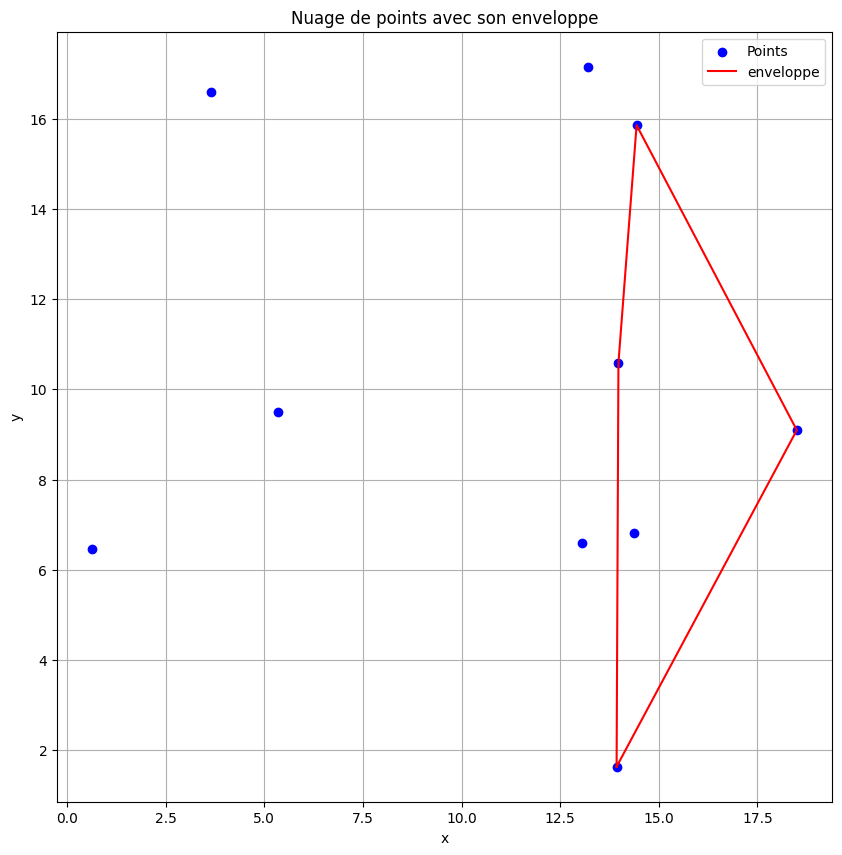

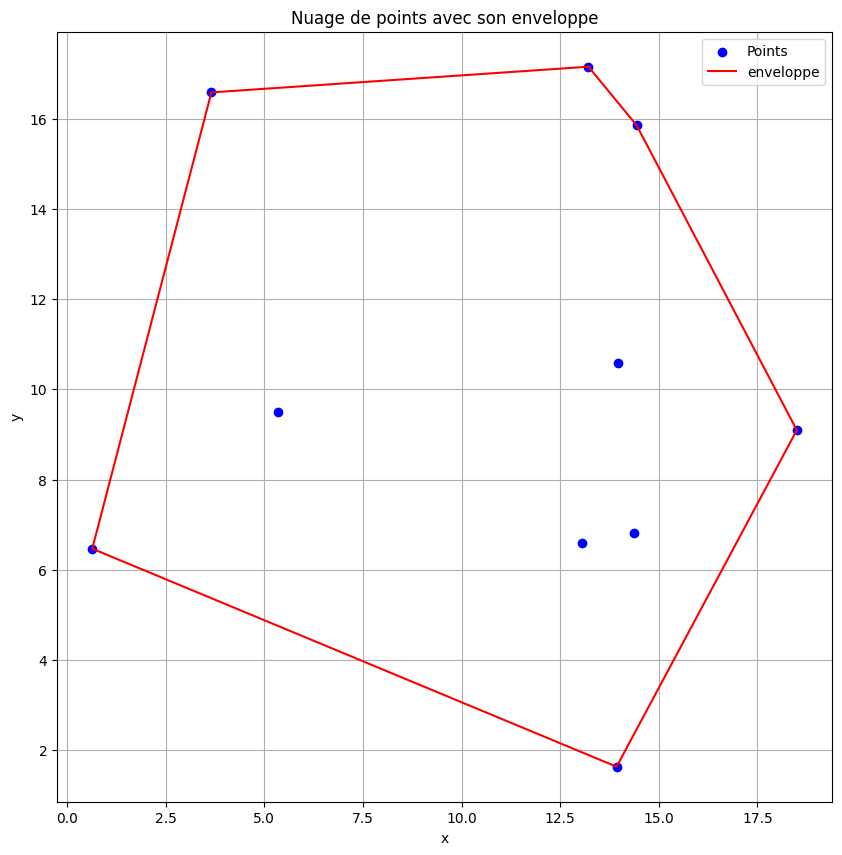

In [155]:

#1ere etape : trie de points en fonction des abscisses croissante
def tri_x_croissant(L_points):
  points=L_points.copy()
  for i in range (0, len(points)):
    i_min=i
    for j in range (i+1, len(points)):
      if points[j][0]<points[i_min][0]:
        i_min=j
    if i_min != i:
      t=points[i]
      points[i]=points[i_min]
      points[i_min]=t
  return points

L_points_tries = tri_x_croissant(nuage)

#2eme etape : "Divide" en coupe au milieu en deux sous groupe puis on applique Sklansky
def divide(L_points):
  L_points_tries = tri_x_croissant(L_points)
  index_milieu = len(L_points_tries)//2
  sous_ensemble_gauche = L_points_tries[:index_milieu]
  sous_ensemble_droite = L_points_tries[index_milieu:]

  gauche=enveloppe_convexe_sklansky(sous_ensemble_gauche)
  droite=enveloppe_convexe_sklansky(sous_ensemble_droite)
  return gauche, droite

gauche, droite = divide(nuage)

tracer_nuage_enveloppe(nuage,gauche)
tracer_nuage_enveloppe(nuage,droite)

#3eme etape : Jonction grâce au tangente, c'est la partie la plus complexe à coder.

#pour la recherche de la tangente il faut savoir si on étudie la tangente du haut ou du bas
#donc on ajoute un argument de type boléen à la fonction pour faire les deux cas
def recherche_tangente(gauche, droite, i, j, sup=True ):
  n_g, n_d =  len(gauche), len(droite)
  m= True #condition de bascullement
  while m :
    m=False
    if sup :
      if produit_vectoriel(droite[j], gauche[i], gauche[(i-1)%n_g])>0:
        i = (i - 1)%(len(gauche))
        m = True
      elif produit_vectoriel(gauche[i], droite[j], droite[(j + 1)%n_d]) < 0:
        j = (j + 1)%(len(droite))
        m = True
    else:
      if produit_vectoriel(gauche[i], droite[j], droite[(j - 1)%n_d])  > 0:
        j = (j - 1)%(len(droite))
        m = True
      elif produit_vectoriel(droite[j], gauche[i], gauche[(i + 1)%n_g])< 0:
        i = (i + 1)%(len(gauche))
        m = True
  return i,j


def point_fusion_enveloppe(gauche, droite):
    n_g, n_d = len(gauche), len(droite)
    i = 0  # On suppose au départ que c'est le 1er point
    for k in range(1, n_g):
      if gauche[k][0] > gauche[i][0]:
        i = k
    j = 0 #de meme à droite
    for k in range(1, n_d):
      if droite[k][0] < droite[j][0]:
        j = k
    return i,j

def jonction(gauche, droite):
  i, j = point_fusion_enveloppe(gauche, droite)
  i_sup, j_sup = recherche_tangente(gauche, droite, i, j, sup=True)
  i_inf, j_inf = recherche_tangente(gauche, droite, i, j, sup=False)

  envellope_fusionnee=[]
  indice_gauche=i_inf
  while indice_gauche != (i_sup+1) %(len(gauche)):
    envellope_fusionnee.append(gauche[indice_gauche])
    indice_gauche=(indice_gauche+1)%(len(gauche))
  indice_droite=j_sup
  while indice_droite != (j_inf+1) % (len(droite)):
    envellope_fusionnee.append(droite[indice_droite])
    indice_droite=(indice_droite+1)%(len(droite))
  return envellope_fusionnee

envellope_fusionnee=jonction(gauche, droite)

def enveloppe_divide_conquer(nuage):
  if len(nuage) <= 2:
    return nuage
  gauche, droite = divide(nuage)
  envellope_fusionnee=jonction(gauche, droite)
  return envellope_fusionnee

tracer_nuage_enveloppe(nuage,envellope_fusionnee)


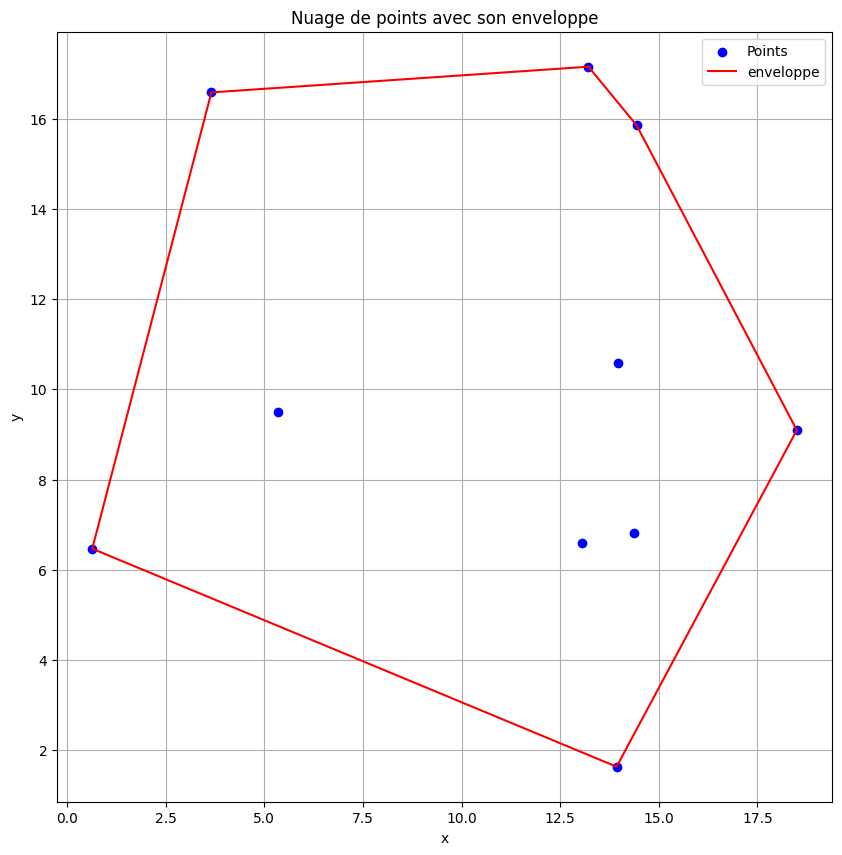

In [156]:
enveloppe=enveloppe_divide_conquer(nuage)
tracer_nuage_enveloppe(nuage,enveloppe)

# Comparaisons

On crée un nuage de points

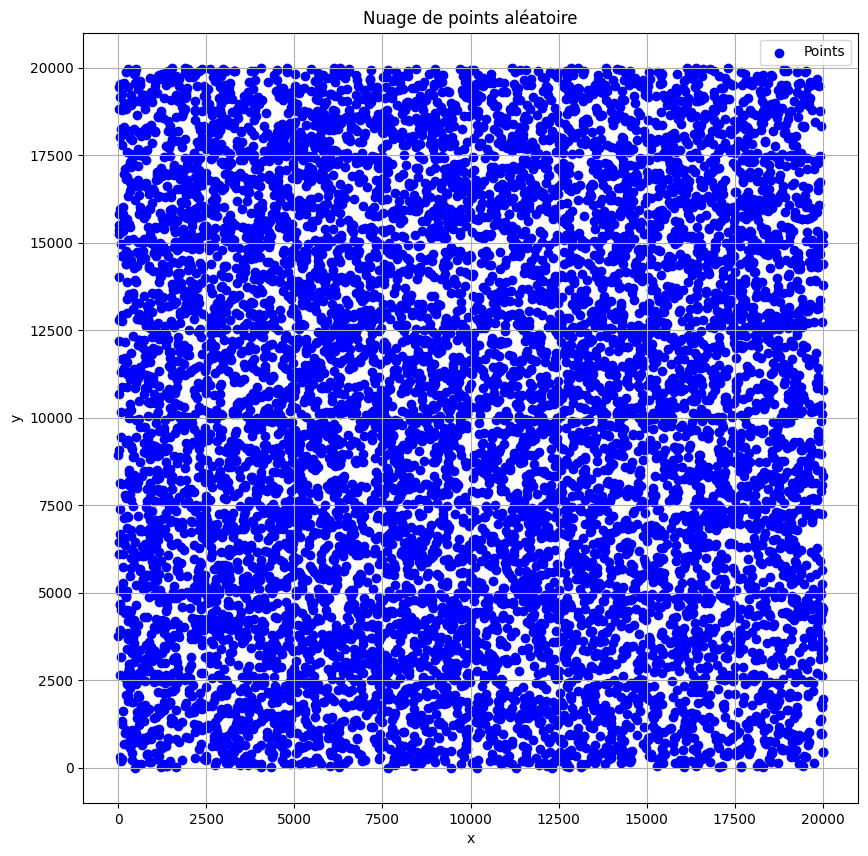

In [157]:
nb_point = 10000
x_min, x_max = 0, 20000
y_min, y_max = 0, 20000
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
tracer_nuage(nuage)

On va comparer les trois méthode

Sklansky


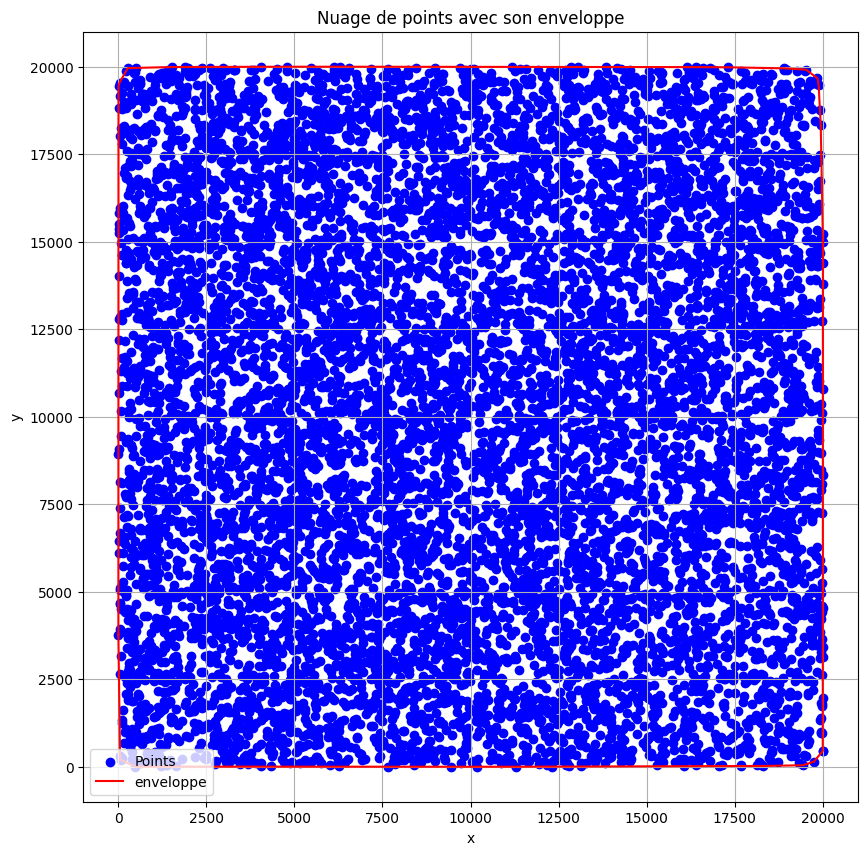

Polaire


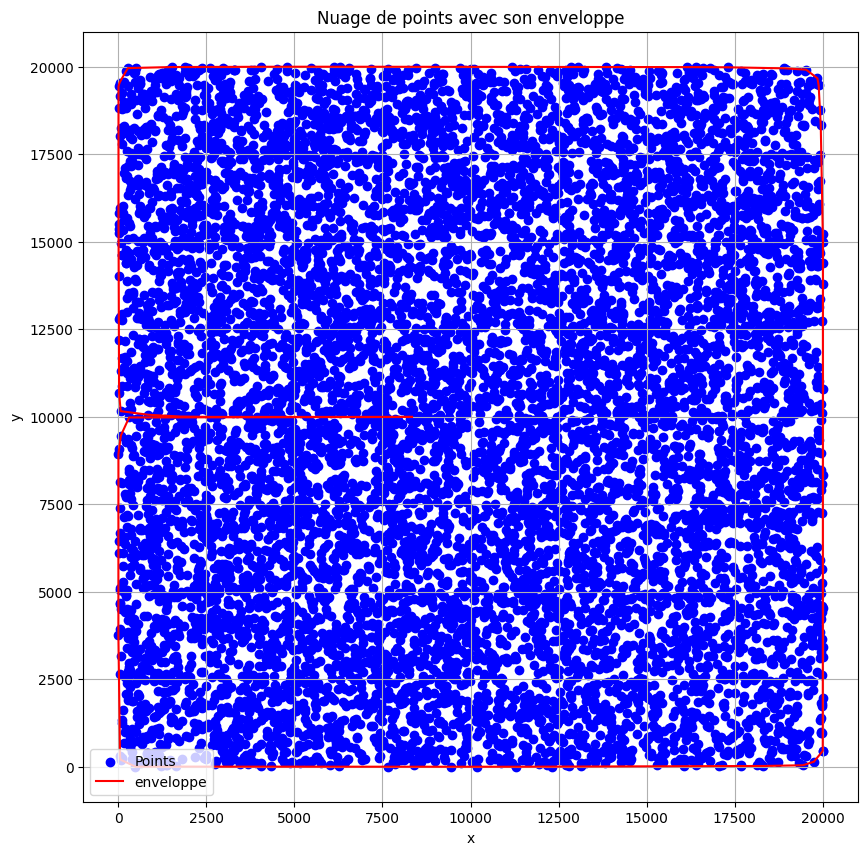

D and C


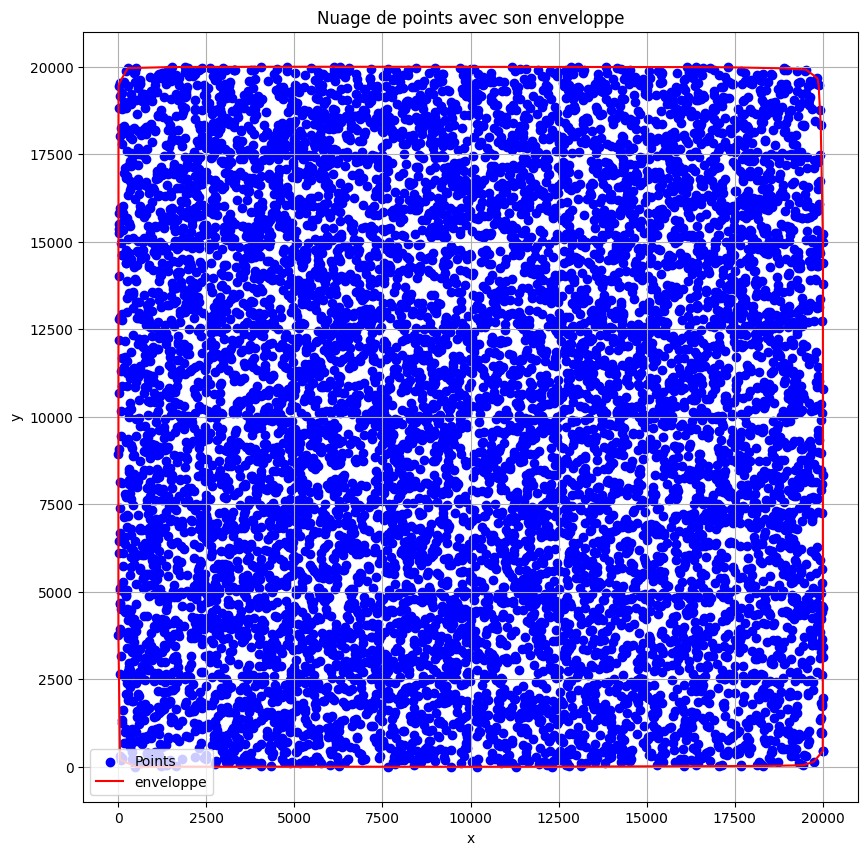

temps pour sklansky : 0.034528493881225586s
temps polaire : 0.039682626724243164s
temps divide and conquer : 4.325165271759033s


In [158]:
# Sklansky
debut1=time.time()
enveloppe1 = enveloppe_convexe_sklansky(sorted(nuage))
fin=time.time()
temps_sklansky=fin-debut1
print('Sklansky')
tracer_nuage_enveloppe(nuage,enveloppe1)

# Polaire
debut2=time.time()
enveloppe2 = enveloppe_convexe_polaire_ter(nuage)
fin=time.time()
temps_polaire=fin-debut2
print('Polaire')
tracer_nuage_enveloppe(nuage,enveloppe2)

# Divide and Conquer
debut3=time.time()
enveloppe3 = enveloppe_divide_conquer(nuage)
fin=time.time()
temps_divide=fin-debut3
print('D and C')
tracer_nuage_enveloppe(nuage,enveloppe3)


print('temps pour sklansky : ' + str(temps_sklansky) + 's')
print('temps polaire : ' + str(temps_polaire) + 's')
print('temps divide and conquer : ' + str(temps_divide) + 's')


On ne prend spas en compte la méthode polaire vu qu'elle ne fonctionne pas. On remarque que sklansky est beaucoup plus rapide que divide and conquer. Cepandant cela provient du fait que le nuage de point est trié par des fonctions qui n'ont pas la même complexité

In [162]:
def divide2(L_points):
  L_points_tries = sorted(L_points)
  index_milieu = len(L_points_tries)//2
  sous_ensemble_gauche = L_points_tries[:index_milieu]
  sous_ensemble_droite = L_points_tries[index_milieu:]

  gauche=enveloppe_convexe_sklansky(sous_ensemble_gauche)
  droite=enveloppe_convexe_sklansky(sous_ensemble_droite)
  return gauche, droite

def enveloppe_divide_conquer2(nuage):
  if len(nuage) <= 2:
    return nuage
  gauche, droite = divide(nuage)
  envellope_fusionnee=jonction(gauche, droite)
  return envellope_fusionnee


In [174]:
# Divide and Conquer
debut3=time.time()
enveloppe3 = enveloppe_divide_conquer2(nuage)
fin=time.time()
temps_divide=fin-debut3
print(temps_divide)

4.866837024688721


Si l'on prend la même fonction de tri pour les 2 méthodes, on retrouve un temps de calcul plus proche entre les 2 méthodes.

In [173]:
nb_point = 10000
x_min, x_max = 0, 200000
y_min, y_max = 0, 200000
nuage = creation_nuage(nb_point,x_min, x_max, y_min, y_max)
#tracer_nuage(nuage)

# Sklansky
debut1=time.time()
enveloppe1 = enveloppe_convexe_sklansky(sorted(nuage))
fin=time.time()
temps_sklansky=fin-debut1
#tracer_nuage_enveloppe(nuage,enveloppe1)


# Divide and Conquer
debut3=time.time()
enveloppe3 = enveloppe_divide_conquer2(nuage)
fin=time.time()
temps_divide=fin-debut3
#tracer_nuage_enveloppe(nuage,enveloppe3)



print('temps pour sklansky : ' + str(temps_sklansky) + 's')
print('temps divide and conquer : ' + str(temps_divide) + 's')

temps pour sklansky : 0.030303239822387695s
temps divide and conquer : 4.111073732376099s


On constate que pour de grand nombre de points, divide and conquer a une complexité temporelle plus élévée que sklansky.